# Scaling Law Experiment — Linear Regression

This notebook implements the synthetic diagonal linear-regression model and compares
**Heavy Ball (HB)**, **Nesterov (NAG)**, and **SGD** under the **same data-budget scaling**.

The scaling is reset to the noisy-interior optimum shown in the attached note. Here we write this quantity explicitly as $1-1/\beta$, so $E_3=2-1/\beta-y+x/\beta$. We use
$B\asymp D^a$, $K\asymp D^{1-a}$, $1-\rho\asymp D^{-b}$, and $\eta\asymp D^{-c}$, with
$x=a+c-b$ and $y=a+b<1$. The noisy-interior exponent is

$$
p^*_{\mathrm{noisy,int}}=
\begin{cases}
s, & s<(1-1/\beta)/2,\\
s \text{ as a supremum}, & s=(1-1/\beta)/2,\\
\dfrac{2s}{2s+1+1/\beta} \text{ as a supremum}, & s>(1-1/\beta)/2.
\end{cases}
$$

We run two experiments: one with $s<(1-1/\beta)/2$ and one with $s>(1-1/\beta)/2$. All three
algorithms use the same $B,K,\eta$ scaling in each experiment; HB and NAG additionally use
the scheduled momentum $\rho$, while SGD keeps $\rho=0$ by definition.


## 1. Setting

$$
\text{Label:}\quad y=\langle\theta^*,x\rangle+\varepsilon,\quad \varepsilon\sim\mathcal{N}(0,\sigma^2)
$$
$$
\text{Data:}\quad x\sim\mathcal{N}(0,H),\qquad H=\mathrm{diag}(\lambda_i),\qquad \lambda_i\asymp i^{-\beta}
$$
$$
\text{Task:}\quad \theta_j^{*\,2}\sim j^{-1-(s-1)\beta}
$$

Because $H$ is diagonal, we work directly in the eigenbasis: each coordinate is independent with
$x_j\sim\mathcal{N}(0,\lambda_j)$. The **population** (test) loss splits into an irreducible part
and the **excess loss**
$$
L(\theta)=\tfrac12\sigma^2+\underbrace{\tfrac12(\theta-\theta^*)^\top H(\theta-\theta^*)}_{\mathcal{E}(\theta)},
\qquad
\mathcal{E}(\theta)=\tfrac12\sum_j \lambda_j\,(\theta_j-\theta_j^*)^2 .
$$
We evaluate $\mathcal{E}$ **analytically** (it is the exact population excess loss), which is both
exact and cheaper than a Monte-Carlo test set.


In [92]:
import numpy as np
import matplotlib.pyplot as plt

# ----------------------------- model / task parameters -----------------------------
BETA  = 3     # spectrum decay lambda_j ~ j^{-beta} (beta > 1)
ONE_MINUS_INV_BETA = 1.0 - 1.0 / BETA  # explicit 1 - 1/beta from E3 = 2 - 1/beta - y + x/beta
SIGMA = 1     # label-noise std
DIM   = 4096    # ambient dimension (truncation of the infinite spectrum)

S_CASES = [
    {'key': 's_lt_one_minus_inv_beta_over_2', 'title': r'$s<(1-1/\beta)/2$', 's': 0.25},
    {'key': 's_gt_one_minus_inv_beta_over_2', 'title': r'$s>(1-1/\beta)/2$', 's': 1.50},
]

def build_problem(dim=DIM, beta=BETA, s=1.0):
    """Return (lam, theta_star) for the diagonal linear-regression problem."""
    j = np.arange(1, dim + 1, dtype=np.float64)
    lam = j ** (-beta)
    var_star = j ** (-(1.0 + (s - 1.0) * beta))
    theta_star = np.sqrt(var_star)
    return lam, theta_star

def excess_loss(delta, lam):
    """Exact population excess loss E = 1/2 * sum_j lam_j * delta_j^2."""
    return 0.5 * np.sum(lam * delta * delta)

print(f'beta={BETA}, 1-1/beta={ONE_MINUS_INV_BETA:.6f}, (1-1/beta)/2={ONE_MINUS_INV_BETA/2:.3f}, sigma={SIGMA}, dim={DIM}')
for case in S_CASES:
    lam, theta_star = build_problem(s=case['s'])
    print(f"{case['title']:>16s}: s={case['s']:.3f}, "
          f"lambda range [{lam[-1]:.2e}, {lam[0]:.2e}], "
          f"initial excess loss E(0)={excess_loss(-theta_star, lam):.4f}")


beta=3, 1-1/beta=0.666667, (1-1/beta)/2=0.333, sigma=1, dim=4096
$s<(1-1/\beta)/2$: s=0.250, lambda range [1.46e-11, 1.00e+00], initial excess loss E(0)=0.9799
$s>(1-1/\beta)/2$: s=1.500, lambda range [1.46e-11, 1.00e+00], initial excess loss E(0)=0.5126


## 2. Data generation & stochastic gradient

For a minibatch of size $B$ we draw fresh samples $x_i\sim\mathcal{N}(0,H)$ and
$y_i=\langle\theta^*,x_i\rangle+\varepsilon_i$. Writing $\delta=\theta-\theta^*$, the empirical
gradient is
$$
\nabla\hat L(\theta)=\frac1B\sum_{i=1}^B\big(\langle\delta,x_i\rangle-\varepsilon_i\big)\,x_i
= H\delta+\xi,\qquad \xi\ \text{the gradient noise}.
$$
We run a **single pass** over the data, so the total number of samples consumed is
$B\cdot K \approx D$ — this is exactly the data budget $D$ used in the scaling analysis.
Tracking $\delta$ directly (instead of $\theta$) is convenient because $\theta^*$ is constant and
all update rules are affine in $\delta$.


In [93]:
def sample_batch(B, lam, sigma=SIGMA, rng=None):
    """Draw a minibatch. Returns X (B,d) with columns scaled by sqrt(lam) and eps (B,)."""
    rng = rng or np.random.default_rng()
    d = lam.shape[0]
    X = rng.standard_normal((B, d)) * np.sqrt(lam)
    eps = rng.standard_normal(B) * sigma
    return X, eps

def grad_delta(delta, X, eps):
    """Stochastic gradient of the empirical loss expressed in delta = theta - theta*."""
    B = X.shape[0]
    resid = X @ delta - eps
    return (X.T @ resid) / B


## 3. Algorithms

All three share the affine recursion in $\delta_t=\theta_t-\theta^*$ (initialised at $\theta_0=0$,
i.e. $\delta_0=-\theta^*$).

**Heavy Ball (HB).**
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t)+\rho\,(\theta_t-\theta_{t-1}).$$

**Nesterov (NAG).** Gradient evaluated at the extrapolated point:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L\big(\theta_t+\rho(\theta_t-\theta_{t-1})\big)+\rho\,(\theta_t-\theta_{t-1}).$$

**SGD.** The special case $\rho=0$:
$$\theta_{t+1}=\theta_t-\eta\,\nabla\hat L(\theta_t).$$

Each step consumes one fresh minibatch of size $B$; we run $K$ steps and return the final excess loss.


In [94]:
def run_optimizer(algo, B, K, eta, rho, lam, theta_star, sigma=SIGMA, rng=None):
    """Run one of {'hb','nag','sgd'} for K steps of batch size B. Returns (final_E, curve)."""
    rng = rng or np.random.default_rng()
    if algo == 'sgd':
        rho = 0.0
    delta = -theta_star.copy()
    delta_prev = delta.copy()
    curve = np.empty(K + 1)
    curve[0] = excess_loss(delta, lam)
    for t in range(K):
        X, eps = sample_batch(B, lam, sigma=sigma, rng=rng)
        momentum = delta - delta_prev
        if algo == 'nag':
            g = grad_delta(delta + rho * momentum, X, eps)
        else:
            g = grad_delta(delta, X, eps)
        delta_new = delta - eta * g + rho * momentum
        delta_prev, delta = delta, delta_new
        curve[t + 1] = excess_loss(delta, lam)
    return curve[-1], curve


## 4. Noisy-interior optimal scaling with the same $B,K,\eta$ for all algorithms

Use the notation from the attached optimality conditions. In this notebook the corresponding term is written explicitly as $1-1/\beta$, matching $E_3=2-1/\beta-y+x/\beta$:

- $B\asymp D^a$,
- $K\asymp D^{1-a}$ so the sample budget is $BK\asymp D$,
- $1-\rho\asymp D^{-b}$,
- $\eta\asymp D^{-c}$,
- $x=a+c-b$, $y=a+b<1$.

For $s<(1-1/\beta)/2$, choose $x=0$, $a=b\in(s/(1-1/\beta),1/2)$, $c=0$, which gives the exponent
$p=s$. For $s>(1-1/\beta)/2$, choose $y<1$ close to one and

$$
x_y=\frac{2s-(1-1/\beta)y}{2s+1+1/\beta},\qquad
 a_y=\frac{x_y+y}{2},\qquad b_y=\frac{y-x_y}{2},\qquad c_y=0.
$$

The plotted theory line uses the exponent actually selected by this strict-interior scaling,

$$
p(y)=s(1-x_y),
$$

and the limiting supremum as $y\uparrow1$ is

$$
p^*=\frac{2s}{2s+1+1/\beta}.
$$


In [95]:
# ----------------------------- common scaling constants -----------------------------
# C_B * C_K ~= 1 keeps the consumed samples B*K at the same order as D.
C_B, C_K = 1.0, 1.0
C_RHO    = 2.0       # 1-rho = C_RHO * D^{-b}; same exponent, safer finite-D damping
C_ETA    = 0.05      # eta = C_ETA * D^{-c}; c=0 in both optimal regimes used here
Y_HIGH   = 0.98      # strict-interior y<1 for the s>(1-1/beta)/2 supremum


def noisy_interior_scaling(s, beta=BETA, y_high=Y_HIGH):
    """Return strict-interior scaling exponents and theoretical decay exponent."""
    one_minus_inv_beta = 1.0 - 1.0 / beta
    threshold = one_minus_inv_beta / 2.0
    if s < threshold:
        a = b = 0.5 * (s / one_minus_inv_beta + 0.5)
        c = 0.0
        x = a + c - b
        y = a + b
        p = s
        p_star = s
        regime = 's < (1-1/beta)/2'
    elif np.isclose(s, threshold):
        a = b = 0.49
        c = 0.0
        x = a + c - b
        y = a + b
        p = s
        p_star = s
        regime = 's = (1-1/beta)/2 (approached)'
    else:
        y = y_high
        x = (2.0 * s - one_minus_inv_beta * y) / (2.0 * s + 1.0 + 1.0 / beta)
        a = 0.5 * (x + y)
        b = 0.5 * (y - x)
        c = 0.0
        p = s * (1.0 - x)
        p_star = 2.0 * s / (2.0 * s + 1.0 + 1.0 / beta)
        regime = 's > (1-1/beta)/2'

    if not (0 <= a <= y < 1 and c >= 0 and a + b < 1):
        raise ValueError(f'infeasible scaling: a={a}, b={b}, c={c}, x={x}, y={y}')
    return {'a': a, 'b': b, 'c': c, 'x': x, 'y': y, 'p': p, 'p_star': p_star, 'regime': regime}


def common_schedule(D, scaling):
    """B,K,eta,rho at data budget D using the same B,K,eta scaling for HB/NAG/SGD."""
    a, b, c = scaling['a'], scaling['b'], scaling['c']
    B = max(1, int(round(C_B * D ** a)))
    K = max(1, int(round(C_K * D ** (1.0 - a))))
    eta = C_ETA * D ** (-c)
    one_minus_rho = min(1.0, C_RHO * D ** (-b))
    rho = 1.0 - one_minus_rho
    return B, K, eta, rho

SCALINGS = {case['key']: noisy_interior_scaling(case['s']) for case in S_CASES}

for case in S_CASES:
    sc = SCALINGS[case['key']]
    print(f"{case['title']}  s={case['s']:.3f}  {sc['regime']}")
    print(f"  exponents: a={sc['a']:.4f}, b={sc['b']:.4f}, c={sc['c']:.4f}, "
          f"x={sc['x']:.4f}, y=a+b={sc['y']:.4f}")
    print(f"  theory exponent used: p={sc['p']:.4f}; supremum p*={sc['p_star']:.4f}")
    for D in [2**10, 2**15]:
        B, K, eta, rho = common_schedule(D, sc)
        print(f"  D=2^{int(np.log2(D)):d}: B={B}, K={K}, eta={eta:.3g}, rho(HB/NAG)={rho:.4f}")
    print()


$s<(1-1/\beta)/2$  s=0.250  s < (1-1/beta)/2
  exponents: a=0.4375, b=0.4375, c=0.0000, x=0.0000, y=a+b=0.8750
  theory exponent used: p=0.2500; supremum p*=0.2500
  D=2^10: B=21, K=49, eta=0.05, rho(HB/NAG)=0.9036
  D=2^15: B=95, K=347, eta=0.05, rho(HB/NAG)=0.9788

$s>(1-1/\beta)/2$  s=1.500  s > (1-1/beta)/2
  exponents: a=0.7608, b=0.2192, c=0.0000, x=0.5415, y=a+b=0.9800
  theory exponent used: p=0.6877; supremum p*=0.6923
  D=2^10: B=195, K=5, eta=0.05, rho(HB/NAG)=0.5624
  D=2^15: B=2724, K=12, eta=0.05, rho(HB/NAG)=0.7953



## 5. Run the two scaling sweeps

For each $s$ regime and each $D$, the three algorithms share the same $B,K,\eta$ schedule.
Only the algorithmic momentum differs: HB and Nesterov use the scheduled $\rho$, while SGD uses
$\rho=0$.


In [96]:
D_EXPONENTS = list(range(10, 16))
D_LIST = [2 ** e for e in D_EXPONENTS]
D_ARRAY = np.array(D_LIST, dtype=float)
N_SEEDS = 3

ALGOS = {
    'HB'      : 'hb',
    'Nesterov': 'nag',
    'SGD'     : 'sgd',
}

CASE_RESULTS = {}

for case in S_CASES:
    key, s = case['key'], case['s']
    lam, theta_star = build_problem(s=s)
    scaling = SCALINGS[key]
    results = {name: {'mean': [], 'std': []} for name in ALGOS}

    print(f"=== {case['title']}  s={s:.3f}; common exponents "
          f"a={scaling['a']:.3f}, b={scaling['b']:.3f}, c={scaling['c']:.3f}; "
          f"theory p={scaling['p']:.3f} ===")

    for D in D_LIST:
        B, K, eta, rho = common_schedule(D, scaling)
        print(f"D=2^{int(np.log2(D)):<2d}  common B={B:<5d} K={K:<5d} eta={eta:.3g} rho={rho:.4f}")
        for name, algo in ALGOS.items():
            vals = []
            for seed in range(N_SEEDS):
                rng = np.random.default_rng(10_000 * seed + 100 * int(10 * s) + D)
                final_E, _ = run_optimizer(algo, B, K, eta, rho, lam, theta_star, rng=rng)
                vals.append(final_E)
            vals = np.array(vals)
            results[name]['mean'].append(vals.mean())
            results[name]['std'].append(vals.std())
            print(f"  {name:9s} E_K={vals.mean():.3e} +/- {vals.std():.1e}")
    CASE_RESULTS[key] = {'case': case, 'scaling': scaling, 'results': results}
    print()


=== $s<(1-1/\beta)/2$  s=0.250; common exponents a=0.438, b=0.438, c=0.000; theory p=0.250 ===
D=2^10  common B=21    K=49    eta=0.05 rho=0.9036
  HB        E_K=2.434e-01 +/- 1.4e-02
  Nesterov  E_K=2.434e-01 +/- 1.1e-02
  SGD       E_K=3.963e-01 +/- 2.3e-03
D=2^11  common B=28    K=73    eta=0.05 rho=0.9288
  HB        E_K=2.025e-01 +/- 1.4e-02
  Nesterov  E_K=2.023e-01 +/- 1.2e-02
  SGD       E_K=3.676e-01 +/- 2.1e-03
D=2^12  common B=38    K=108   eta=0.05 rho=0.9474
  HB        E_K=1.935e-01 +/- 2.4e-02
  Nesterov  E_K=1.802e-01 +/- 1.3e-02
  SGD       E_K=3.397e-01 +/- 2.6e-03
D=2^13  common B=52    K=159   eta=0.05 rho=0.9612
  HB        E_K=1.480e-01 +/- 1.4e-02
  Nesterov  E_K=1.439e-01 +/- 7.0e-03
  SGD       E_K=3.008e-01 +/- 2.3e-03
D=2^14  common B=70    K=235   eta=0.05 rho=0.9713
  HB        E_K=1.181e-01 +/- 3.7e-03
  Nesterov  E_K=1.157e-01 +/- 1.2e-03
  SGD       E_K=2.728e-01 +/- 9.7e-04
D=2^15  common B=95    K=347   eta=0.05 rho=0.9788
  HB        E_K=1.022e-01 +/-

## 6. Log–log plots: excess loss vs. $D$ with theoretical lines

Each panel corresponds to one $s$ regime. The dashed line is anchored at the first HB point and
has slope $-p$, where $p$ is the exponent selected by the strict-interior scaling above.


$s<(1-1/\beta)/2$  s=0.250: theory slope = -0.2500 (supremum slope = -0.2500)
  measured slope HB       : -0.2566
  measured slope Nesterov : -0.2637
  measured slope SGD      : -0.1381

$s>(1-1/\beta)/2$  s=1.500: theory slope = -0.6877 (supremum slope = -0.6923)
  measured slope HB       : -0.8814
  measured slope Nesterov : -0.9785
  measured slope SGD      : -0.1947



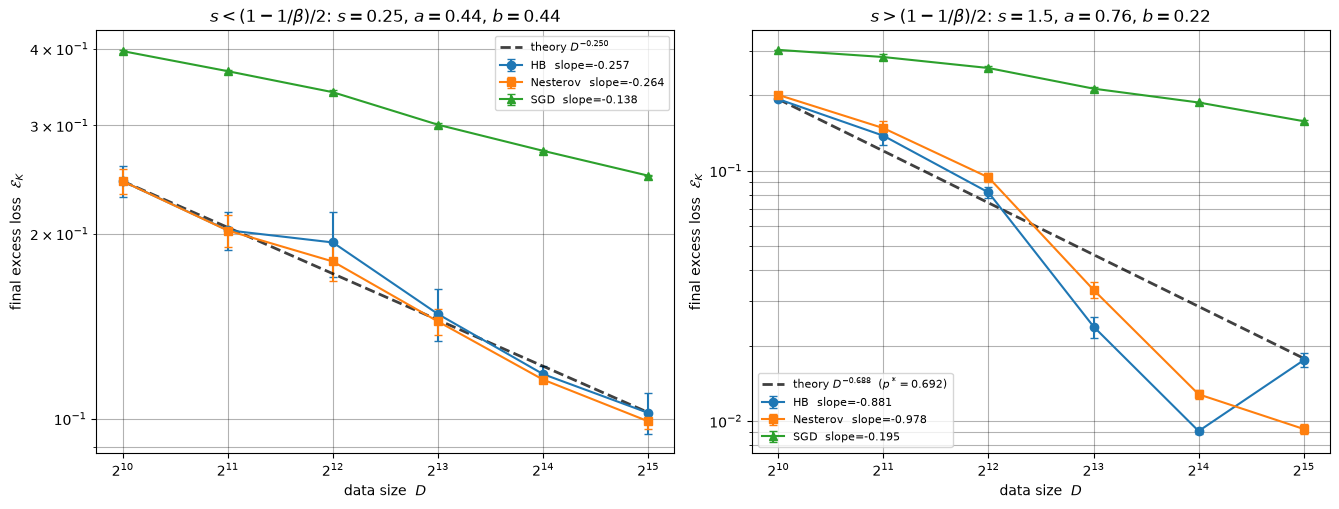

In [97]:
fig, axes = plt.subplots(1, len(S_CASES), figsize=(13.5, 5.2), sharey=False)
if len(S_CASES) == 1:
    axes = [axes]

markers = {'HB': 'o', 'Nesterov': 's', 'SGD': '^'}

for ax, case in zip(axes, S_CASES):
    key = case['key']
    payload = CASE_RESULTS[key]
    scaling = payload['scaling']
    results = payload['results']
    p_theory = scaling['p']
    slopes = {}

    for name in ALGOS:
        mean = np.array(results[name]['mean'])
        std = np.array(results[name]['std'])
        slope, intercept = np.polyfit(np.log(D_ARRAY), np.log(mean), 1)
        slopes[name] = slope
        ax.errorbar(D_LIST, mean, yerr=std, marker=markers[name], capsize=3,
                    linestyle='-', label=f'{name}  slope={slope:.3f}')

    anchor = np.array(results['HB']['mean'])[0]
    ref = anchor * (D_ARRAY / D_ARRAY[0]) ** (-p_theory)
    theory_label = rf'theory $D^{{-{p_theory:.3f}}}$'
    if scaling['p_star'] > p_theory + 1e-10:
        theory_label += rf'  ($p^*={scaling["p_star"]:.3f}$)'
    ax.plot(D_LIST, ref, linestyle='--', color=(0, 0, 0, 0.75), linewidth=2, label=theory_label)

    ax.set_xscale('log', base=2)
    ax.set_yscale('log')
    ax.set_xlabel('data size  $D$')
    ax.set_ylabel(r'final excess loss  $\mathcal{E}_K$')
    ax.set_title(rf"{case['title']}: $s={case['s']}$, $a={scaling['a']:.2f}$, $b={scaling['b']:.2f}$")
    ax.grid(True, which='both', color=(0, 0, 0, 0.3))
    ax.legend(fontsize=8)

    print(f"{case['title']}  s={case['s']:.3f}: theory slope = {-p_theory:.4f} "
          f"(supremum slope = {-scaling['p_star']:.4f})")
    for name, sl in slopes.items():
        print(f'  measured slope {name:9s}: {sl:.4f}')
    print()

plt.tight_layout()
plt.show()


## 7. Training curves for representative $D$

These curves are diagnostic only. The scaling-law comparison above uses final excess loss at fixed
sample budget $D$.


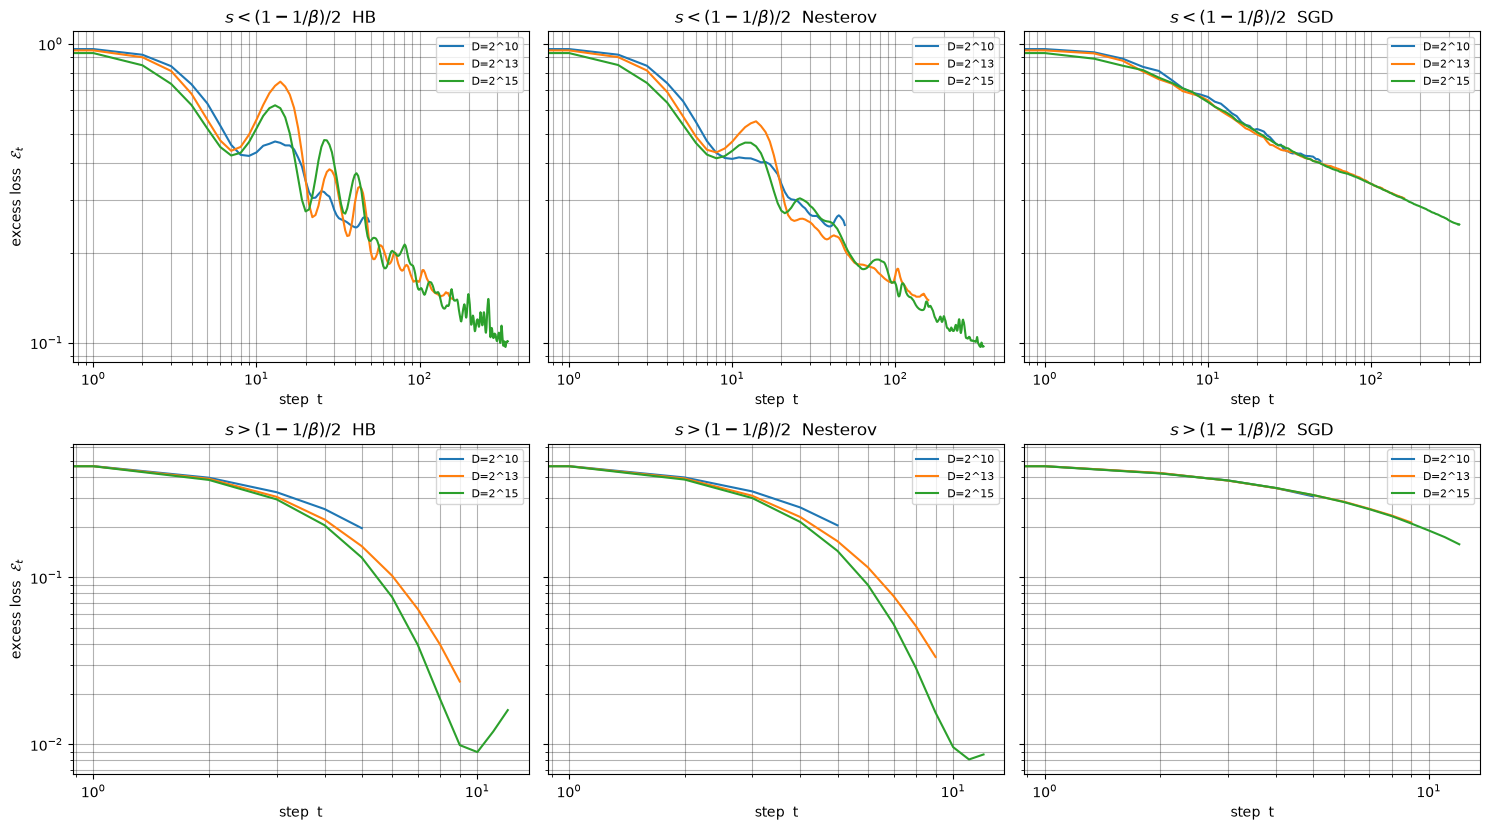

In [98]:
rep_D = [2 ** e for e in (D_EXPONENTS[0], D_EXPONENTS[len(D_EXPONENTS)//2], D_EXPONENTS[-1])]
fig, axes = plt.subplots(len(S_CASES), len(ALGOS), figsize=(15, 4.2 * len(S_CASES)), sharey='row')
if len(S_CASES) == 1:
    axes = np.array([axes])

for row, case in enumerate(S_CASES):
    key, s = case['key'], case['s']
    scaling = SCALINGS[key]
    lam, theta_star = build_problem(s=s)
    for col, (name, algo) in enumerate(ALGOS.items()):
        ax = axes[row, col]
        for D in rep_D:
            B, K, eta, rho = common_schedule(D, scaling)
            rng = np.random.default_rng(D + 123 * row)
            _, curve = run_optimizer(algo, B, K, eta, rho, lam, theta_star, rng=rng)
            ax.plot(np.arange(len(curve)), curve, label=f'D=2^{int(np.log2(D))}')
        ax.set_xscale('log')
        ax.set_yscale('log')
        ax.set_title(f"{case['title']}  {name}")
        ax.set_xlabel('step  t')
        ax.grid(True, which='both', color=(0, 0, 0, 0.3))
        ax.legend(fontsize=8)
    axes[row, 0].set_ylabel(r'excess loss  $\mathcal{E}_t$')

plt.tight_layout()
plt.show()


## 8. Expected outcome

The experiment now tests the noisy-interior optimal conditions directly.

- For $s<(1-1/\beta)/2$, the chosen scaling has $x=0$, $a=b\in(s/(1-1/\beta),1/2)$, $c=0$, so the
  theory line has exponent $p=s$.
- For $s>(1-1/\beta)/2$, the chosen strict-interior scaling uses $y<1$ close to one. The plotted
  exponent is $p(y)=s(1-x_y)$, and it approaches the supremum
  $p^*=2s/(2s+1+1/\beta)$ as $y\uparrow1$.
- HB, Nesterov, and SGD share the same $B,K,\eta$ exponents in each panel. SGD keeps
  $\rho=0$ because it has no momentum term, while HB/NAG use the common momentum scaling.

Finite-dimensional truncation, constants, and stochastic variance can move the fitted slopes, but
the dashed reference lines show the theoretical polynomial rates implied by the selected scaling.
